# Double-slit diffraction with a spatially incoherent source 

This example uses the paper's $F_1=F_2=0.2$, $\theta_0=20^\circ$ geometry.

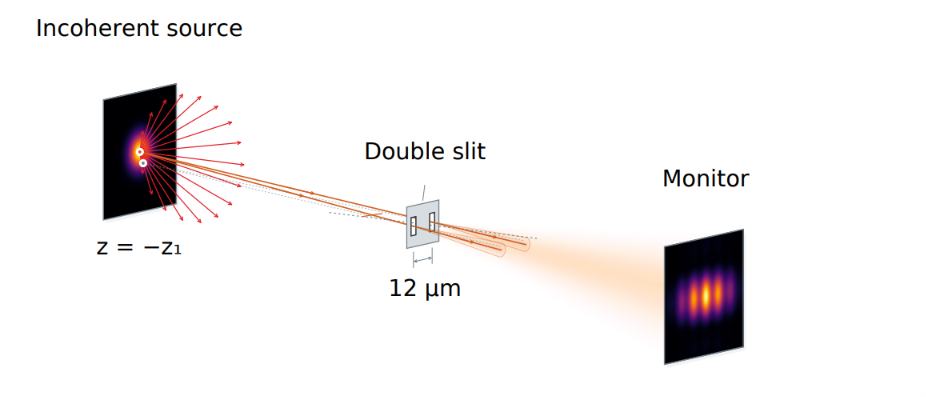

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import jax
jax.config.update("jax_enable_x64", True)

import diffractsim
diffractsim.set_backend("JAX")
from diffractsim import IncoherentLightSimulation, ApertureFromFunction, um
from diffractsim.util.backend_functions import backend as bd
plt.rcParams["figure.dpi"] = 150

## 1. Set the source and aperture

The source lies at $z=-z_1$, the pupil at $z=0$, and the monitor at $z=z_2$. At $\lambda=1\,\mu\mathrm{m}$, the two slits have width $w=3.125\,\mu\mathrm{m}$, height $h=7.125\,\mu\mathrm{m}$, and centre separation $D=12\,\mu\mathrm{m}$. We set the distances through $F_i=a^2/(\lambda z_i)$, giving $z_1=z_2\simeq349.414\,\mu\mathrm{m}$.

The source irradiance used here is:
$$
L_0(z_1\mathbf{t})=
\frac{L_*}{2\pi\sigma_t^2}
\exp\!\left[-\frac{|\mathbf{t}-\mathbf{t}_0|^2}{2\sigma_t^2}\right],
\qquad \mathbf{t}_0=(\tan\theta_0,0).
\tag{27}
$$
where  $\mathbf{t}=(x',y')/z_1$


`extended_source_fun` implements this radiance, and `finite_double_slit_aperture` defines the pupil transmission $\mathscr{P}(\xi,\eta)$. 
`set_illumination_from_plane` set the source $L_{\mathrm{in}}(x',y')$


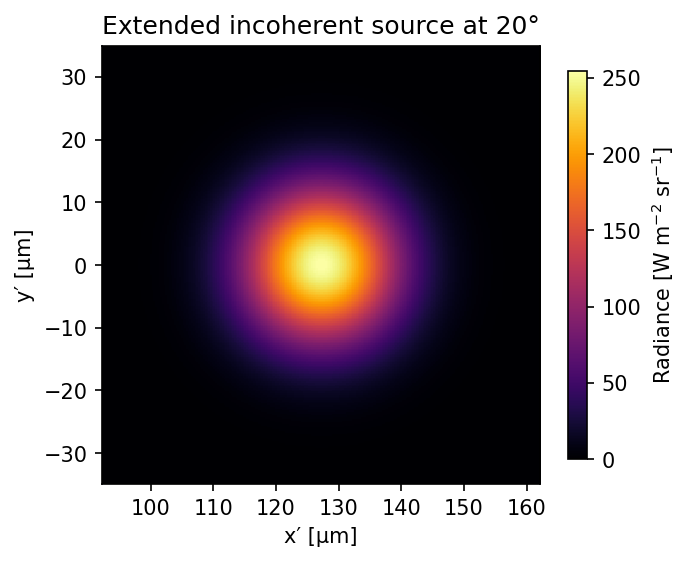

<Axes: title={'center': 'Extended incoherent source at 20°'}, xlabel='x′ [µm]', ylabel='y′ [µm]'>

In [3]:
##############################################################
# set up the source
##############################################################

wavelength = 1*um
separation, slit_width, slit_height = 12*um, 3.125*um, 7.125*um
F1, F2, theta0 = 0.2, 0.2, np.deg2rad(20)
sigma_t, radiance_scale = 0.025, 1.0
a = np.hypot((separation+slit_width)/2, slit_height/2)
z1, z2 = a*a/(wavelength*F1), a*a/(wavelength*F2)

def extended_source_fun(x, y):
    """Gaussian radiance of an extended incoherent source."""
    r2 = (x/z1-np.tan(theta0))**2+(y/z1)**2
    return radiance_scale*bd.exp(-r2/(2*sigma_t**2))/(2*bd.pi*sigma_t**2)

sim = IncoherentLightSimulation(λ=wavelength, extent_x=32*um, extent_y=32*um, Nx=768, Ny=768)
sim.set_illumination_from_plane(extended_source_fun, z1, paraxial=False, angular_samples=2048)

source_x, source_span = z1*np.tan(theta0), 4*z1*sigma_t
sim.plot_illumination_plane( units=um, figsize=(4.5, 3.8), title=f"Extended incoherent source at {np.rad2deg(theta0):g}°",xlim=(source_x-source_span, source_x+source_span),ylim=(-source_span, source_span))

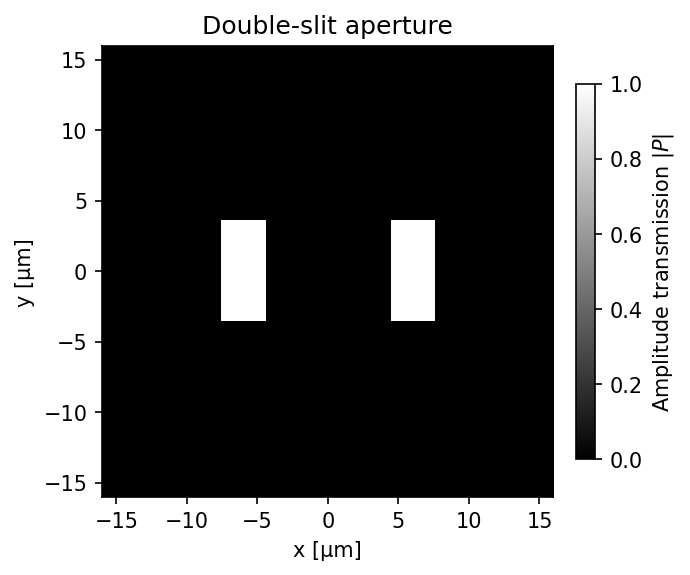

<Axes: title={'center': 'Double-slit aperture'}, xlabel='x [µm]', ylabel='y [µm]'>

In [7]:
##############################################################
# set up the double slit
##############################################################

def finite_double_slit_aperture(x, y, wavelength):
    """Two rectangular transmitting slits, centred at x = ±separation/2."""
    left = abs(x+separation/2) < slit_width/2
    right = abs(x-separation/2) < slit_width/2
    return ((left | right) & (abs(y) < slit_height/2)).astype(float)

slit_aperture = ApertureFromFunction(finite_double_slit_aperture)

sim.plot_aperture(slit_aperture, units=um, figsize=(4.5, 3.8), title="Double-slit aperture")

## 2. Propagate to the monitor plane and inspect the monitor irradiance




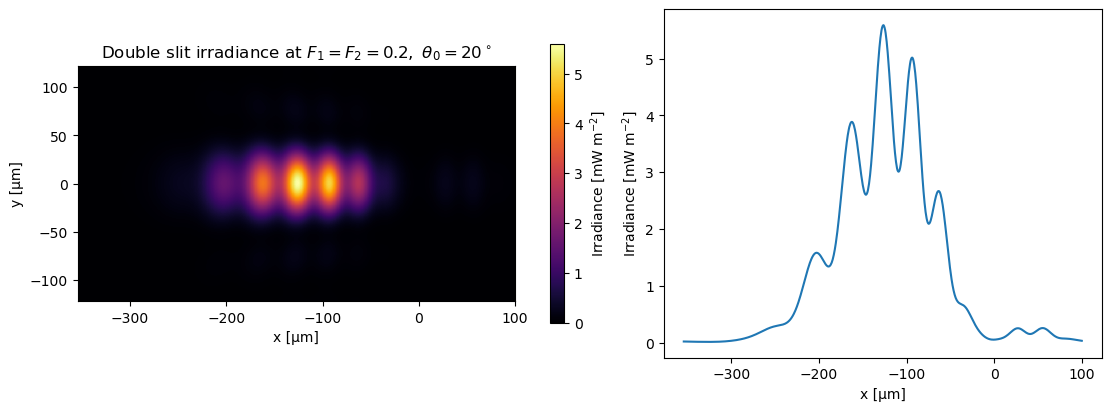

<Axes: title={'center': 'Double slit irradiance at $F_1=F_2=0.2,\\ \\theta_0=20^\\circ$'}, xlabel='x [µm]', ylabel='y [µm]'>

In [8]:
# 2. Eq. (24) irradiance and its horizontal y = 0 slice.
def optical_setup(F, z):
    """Apply the two slits and propagate to the finite monitor."""
    F = F.add(slit_aperture)
    F = F.zoom_propagate(z, x_interval=[z*(-0.65-np.tan(theta0)), z*(0.65-np.tan(theta0))], y_interval=[-0.35*z, 0.35*z],
        model="Fresnel", sampling="angular")
    return F

x_slit, y_slit, E_slit = sim.get_irradiance(optical_setup, z2)
sim.plot_irradiance(E_slit, units=um, irradiance_units=1e-3, slice_y_pos=0, figsize=(11, 4), cmap="inferno",text=r"Double slit irradiance at $F_1=F_2=0.2,\ \theta_0=20^\circ$")

## 3. Broaden the source and watch the fringes fade

We now keep the slits, distances and source centre fixed and vary only the Gaussian width $\sigma_t$ in Eq. (27). The three values below give an almost coherent illumination, the previous example, and a broad source that nearly washes out the fringes.

Each source point produces a displaced interference pattern. As the source broadens, adding these intensities fills the dark fringes and reduces their visibility. The Gaussian normalization keeps the source-plane integral of $L_0$ fixed.


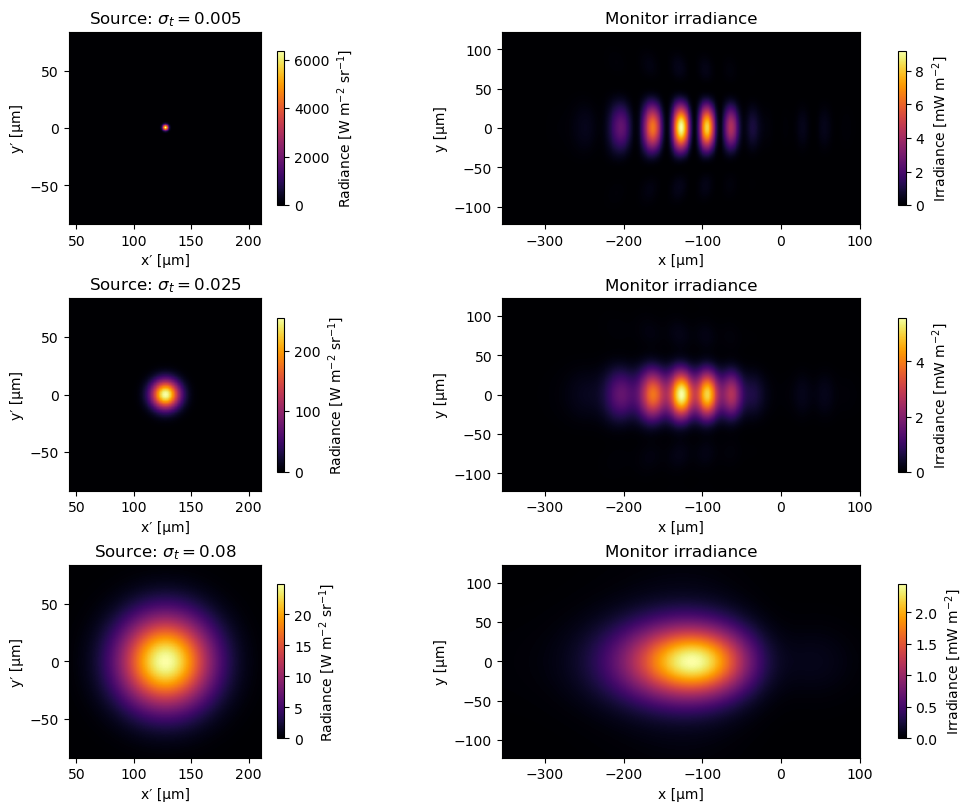

In [9]:
# 3. The same optical setup under three source widths.
source_widths = [0.005, 0.025, 0.08]
comparison_span = 3*z1*max(source_widths)
comparison = IncoherentLightSimulation(sim.λ, sim.extent_x, sim.extent_y, sim.Nx, sim.Ny)

fig, axes = plt.subplots(3, 2, figsize=(10, 8), layout="constrained",
                         gridspec_kw={"width_ratios": [1, 1.7]})
for row, width in enumerate(source_widths):
    def source(x, y, sigma=width):
        """Gaussian radiance with this row's source width."""
        r2 = (x/z1-np.tan(theta0))**2+(y/z1)**2
        return radiance_scale*bd.exp(-r2/(2*sigma**2))/(2*bd.pi*sigma**2)

    comparison.set_illumination_from_plane(source, z1, paraxial=sim.paraxial,
        angular_samples=sim.angular_samples)
    x, y, E = comparison.get_irradiance(optical_setup, z2)

    comparison.plot_illumination_plane(units=um, samples=513, ax=axes[row, 0],
        xlim=(source_x-comparison_span, source_x+comparison_span),
        ylim=(-comparison_span, comparison_span),
        title=rf"Source: $\sigma_t={width:g}$")
    comparison.plot_map(x, y, E/1e-3, units=um, ax=axes[row, 1],
        labels=("x [µm]", "y [µm]"), colorbar_label=r"Irradiance [mW m$^{-2}$]",
        title="Monitor irradiance", cmap="inferno", vmin=0)
plt.show()